<a href="https://colab.research.google.com/github/PabloShol/simulacion2/blob/main/Black_Scholes_Sympy.ipynb" target="_parent"><img src="https://colab.research.google.com/assets/colab-badge.svg" alt="Open In Colab"/></a>

        2                                                      
     2 ∂                                                       
841⋅S ⋅───(V(S, t))     ∂                                      
         2            S⋅──(V(S, t))                            
       ∂S               ∂S            V(S, t)   ∂              
─────────────────── + ───────────── - ─────── + ──(V(S, t)) = 0
       20000               25           25      ∂t             

             ⎧S - 60  for S ≥ 60
V(S, 3/10) = ⎨                  
             ⎩  0     otherwise 

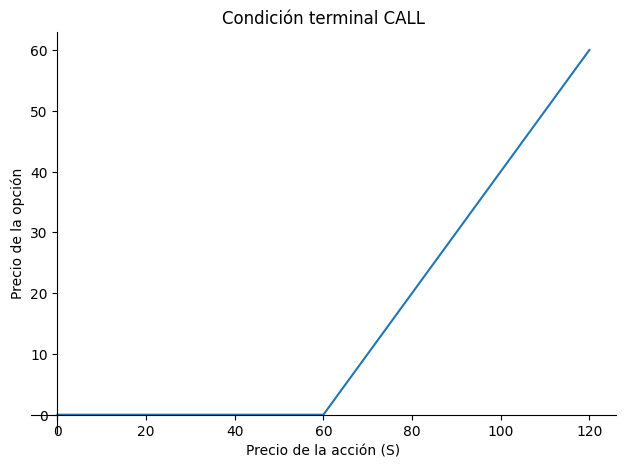

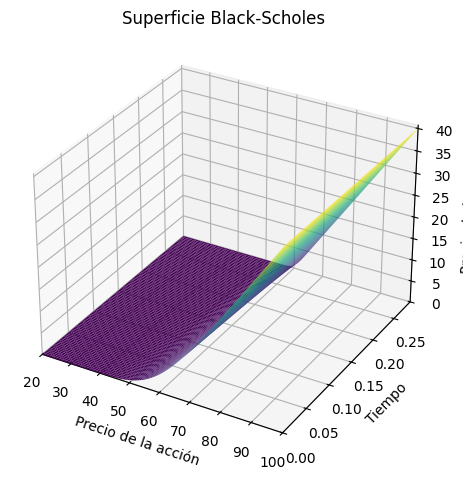

d1 = -0.00442464122517600
d2 = -0.163264182901674
Precio de la opción: 3.34886


In [1]:
import sympy as sy
from sympy.plotting import plot3d
sy.init_printing()

# 1. Ecuación de Black-Scholes
S, t = sy.symbols('S t', positive=True)
V = sy.Function('V')(S, t)

sigma, r, q = sy.Rational(29,100), sy.Rational(4,100), 0
E, T = 60, sy.Rational(3,10)

ecuacion = sy.diff(V,t) + sigma**2*S**2/2*sy.diff(V,S,2) + (r-q)*S*sy.diff(V,S) - r*V
display(sy.Eq(ecuacion, 0))

# 2. Condición terminal
condicion = sy.Piecewise((S-E, S>=E), (0, True))
display(sy.Eq(V.subs(t,T), condicion))

# 3. Gráfica de la condición terminal
sy.plot(condicion, (S, 0, 120), title='Condición terminal CALL',
        xlabel='Precio de la acción (S)', ylabel='Precio de la opción')

# 4. Fórmula de Black-Scholes
d1 = ((r-q+sigma**2/2)*(T-t) + sy.log(S/E)) / (sigma*sy.sqrt(T-t))
d2 = d1 - sigma*sy.sqrt(T-t)
N = lambda d: (1 + sy.erf(d/sy.sqrt(2)))/2
solucion = S*sy.exp(-q*(T-t))*N(d1) - E*sy.exp(-r*(T-t))*N(d2)

# 5. Gráfica de la solución
plot3d(solucion, (S, 20, 100), (t, 0, 0.29), title='Superficie Black-Scholes',
       xlabel='Precio de la acción', ylabel='Tiempo', zlabel='Precio de la opción')

# 6. Precio actual de IBM
print("d1 =", sy.N(d1.subs({S:58.5, t:0})))
print("d2 =", sy.N(d2.subs({S:58.5, t:0})))
print("Precio de la opción:", sy.N(solucion.subs({S:58.5, t:0}), 6))